<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Political_Accountability_and_Enforcement_Pathways_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

A Monte Carlo decision tree of public pressure, political protection, recurring barriers, and judicial outcomes.

In [ ]:
!uv pip install graphviz ipython matplotlib numpy

Using Python 3.13.16 environment at: /usr
Resolved 26 packages in 234ms
Prepared 1 package in 263ms
Installed 1 package in 157ms
 + jedi==0.20.0


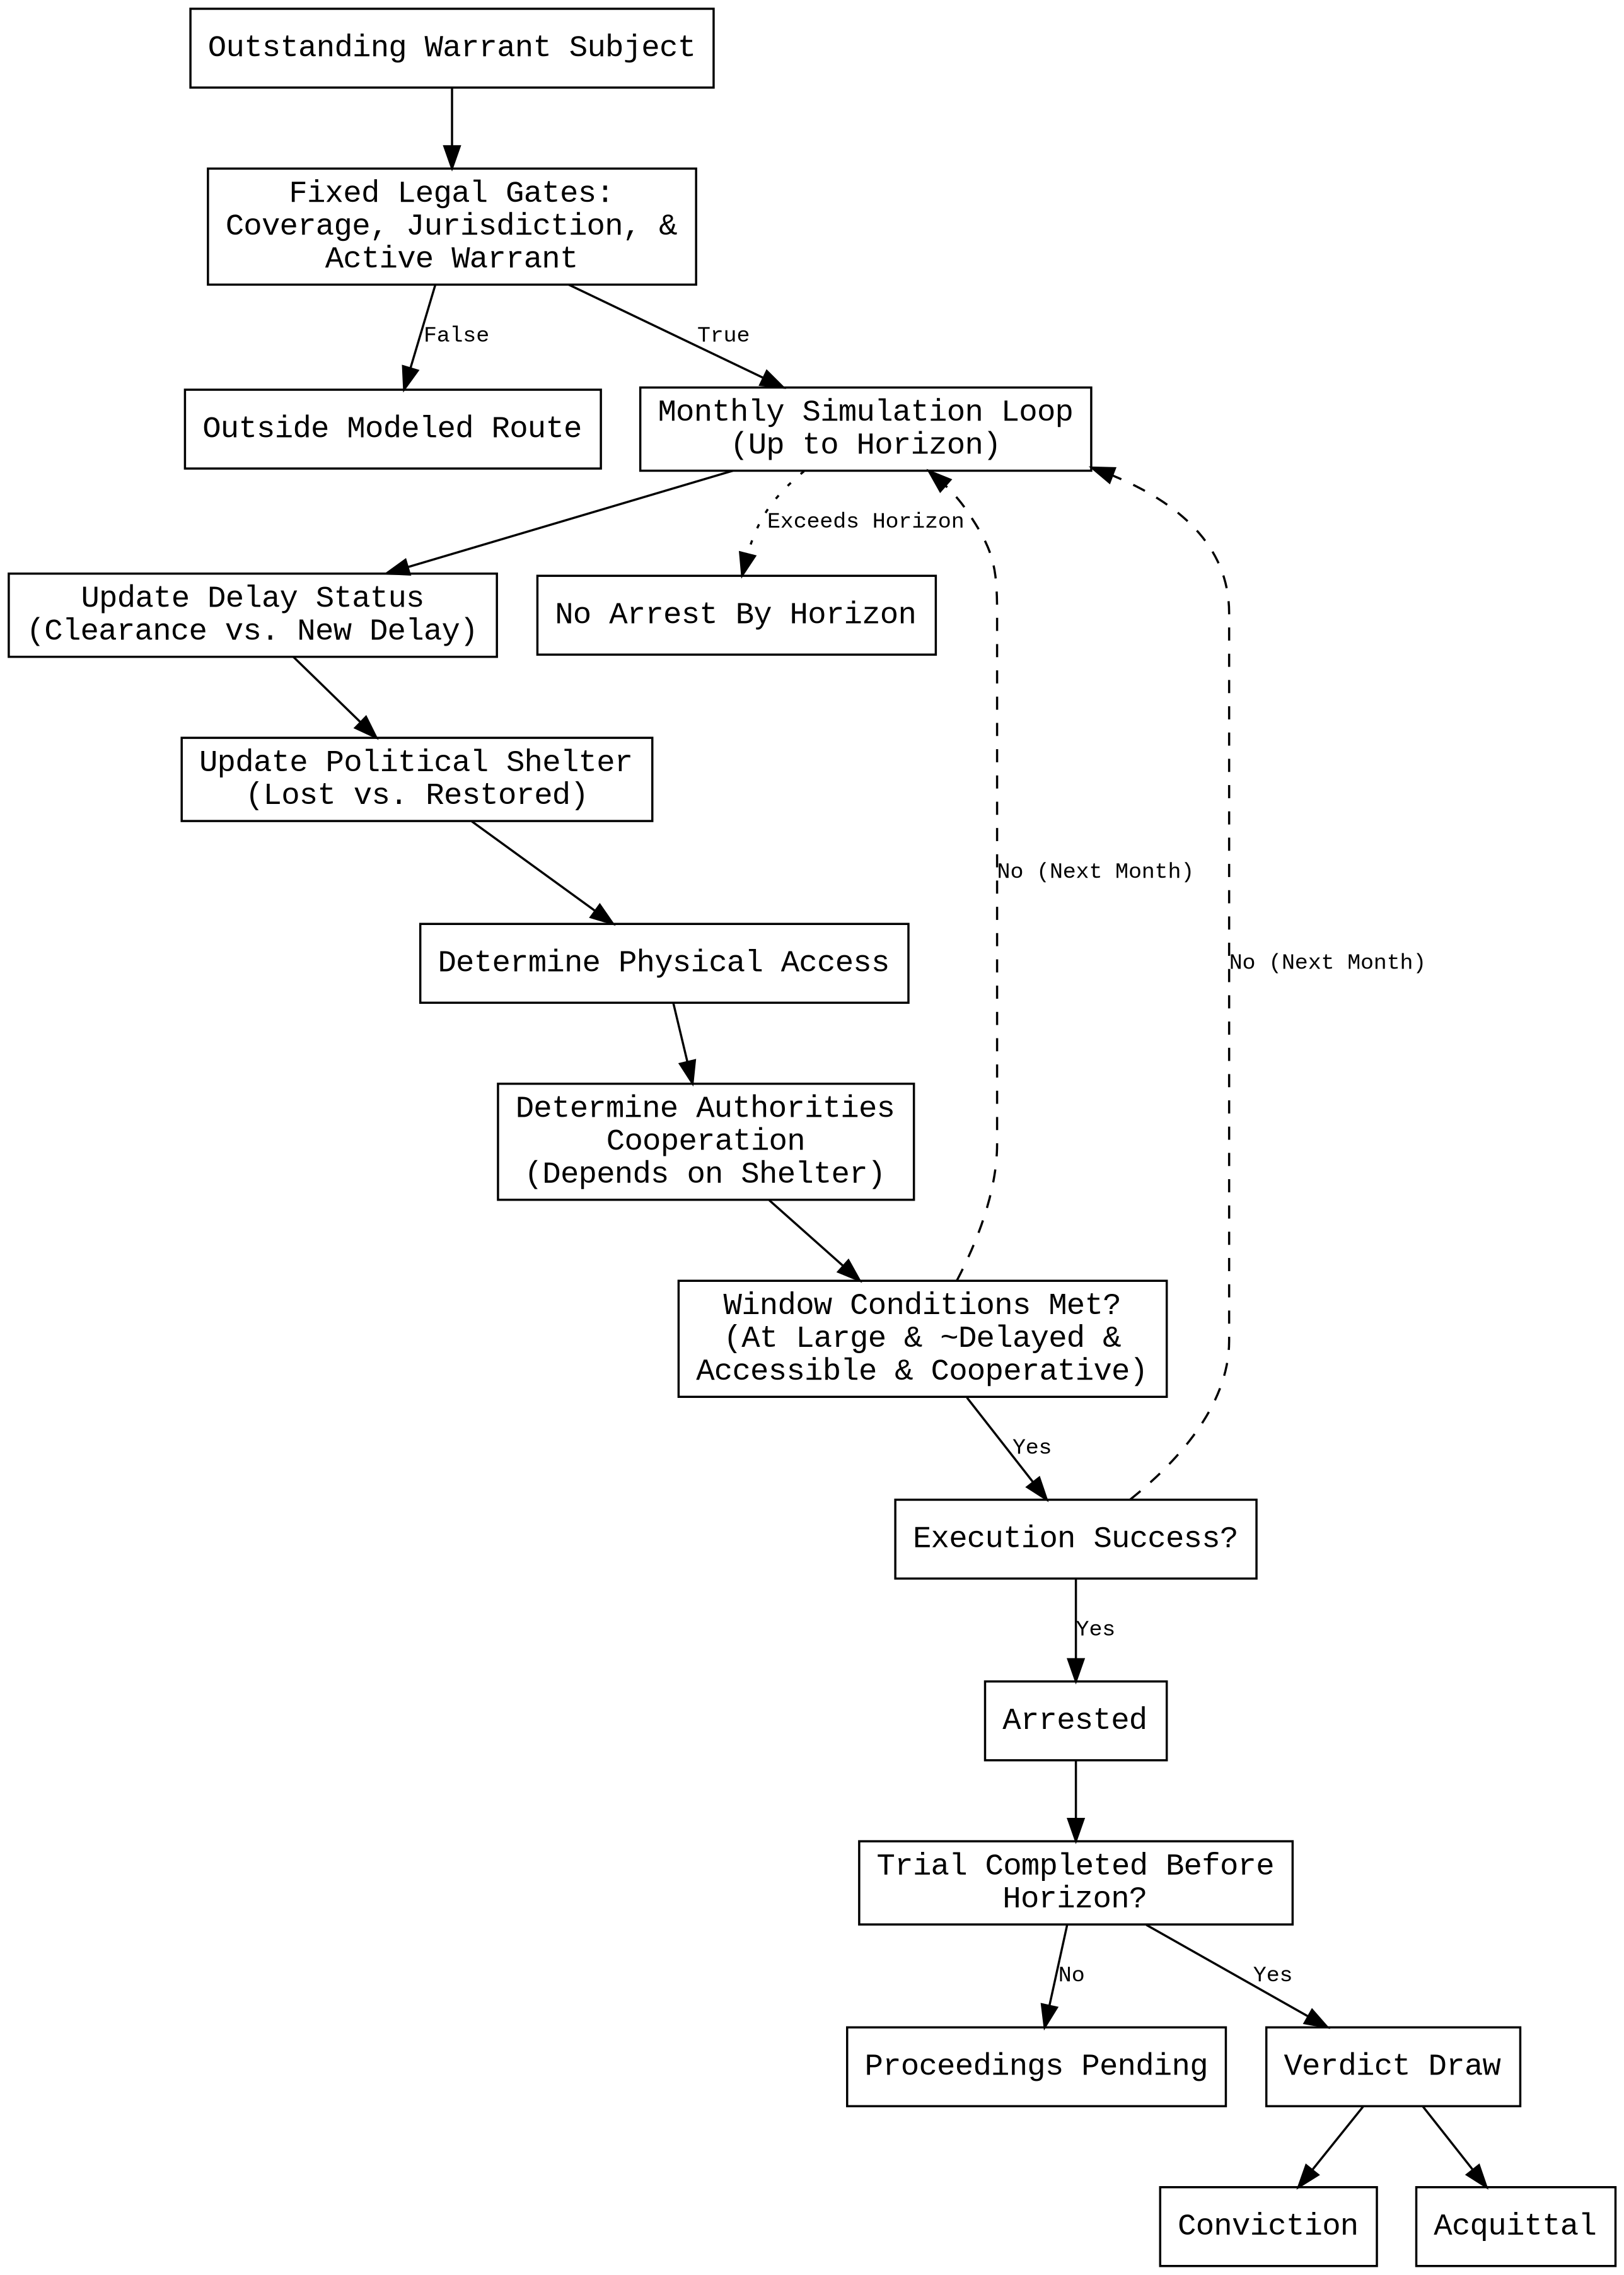


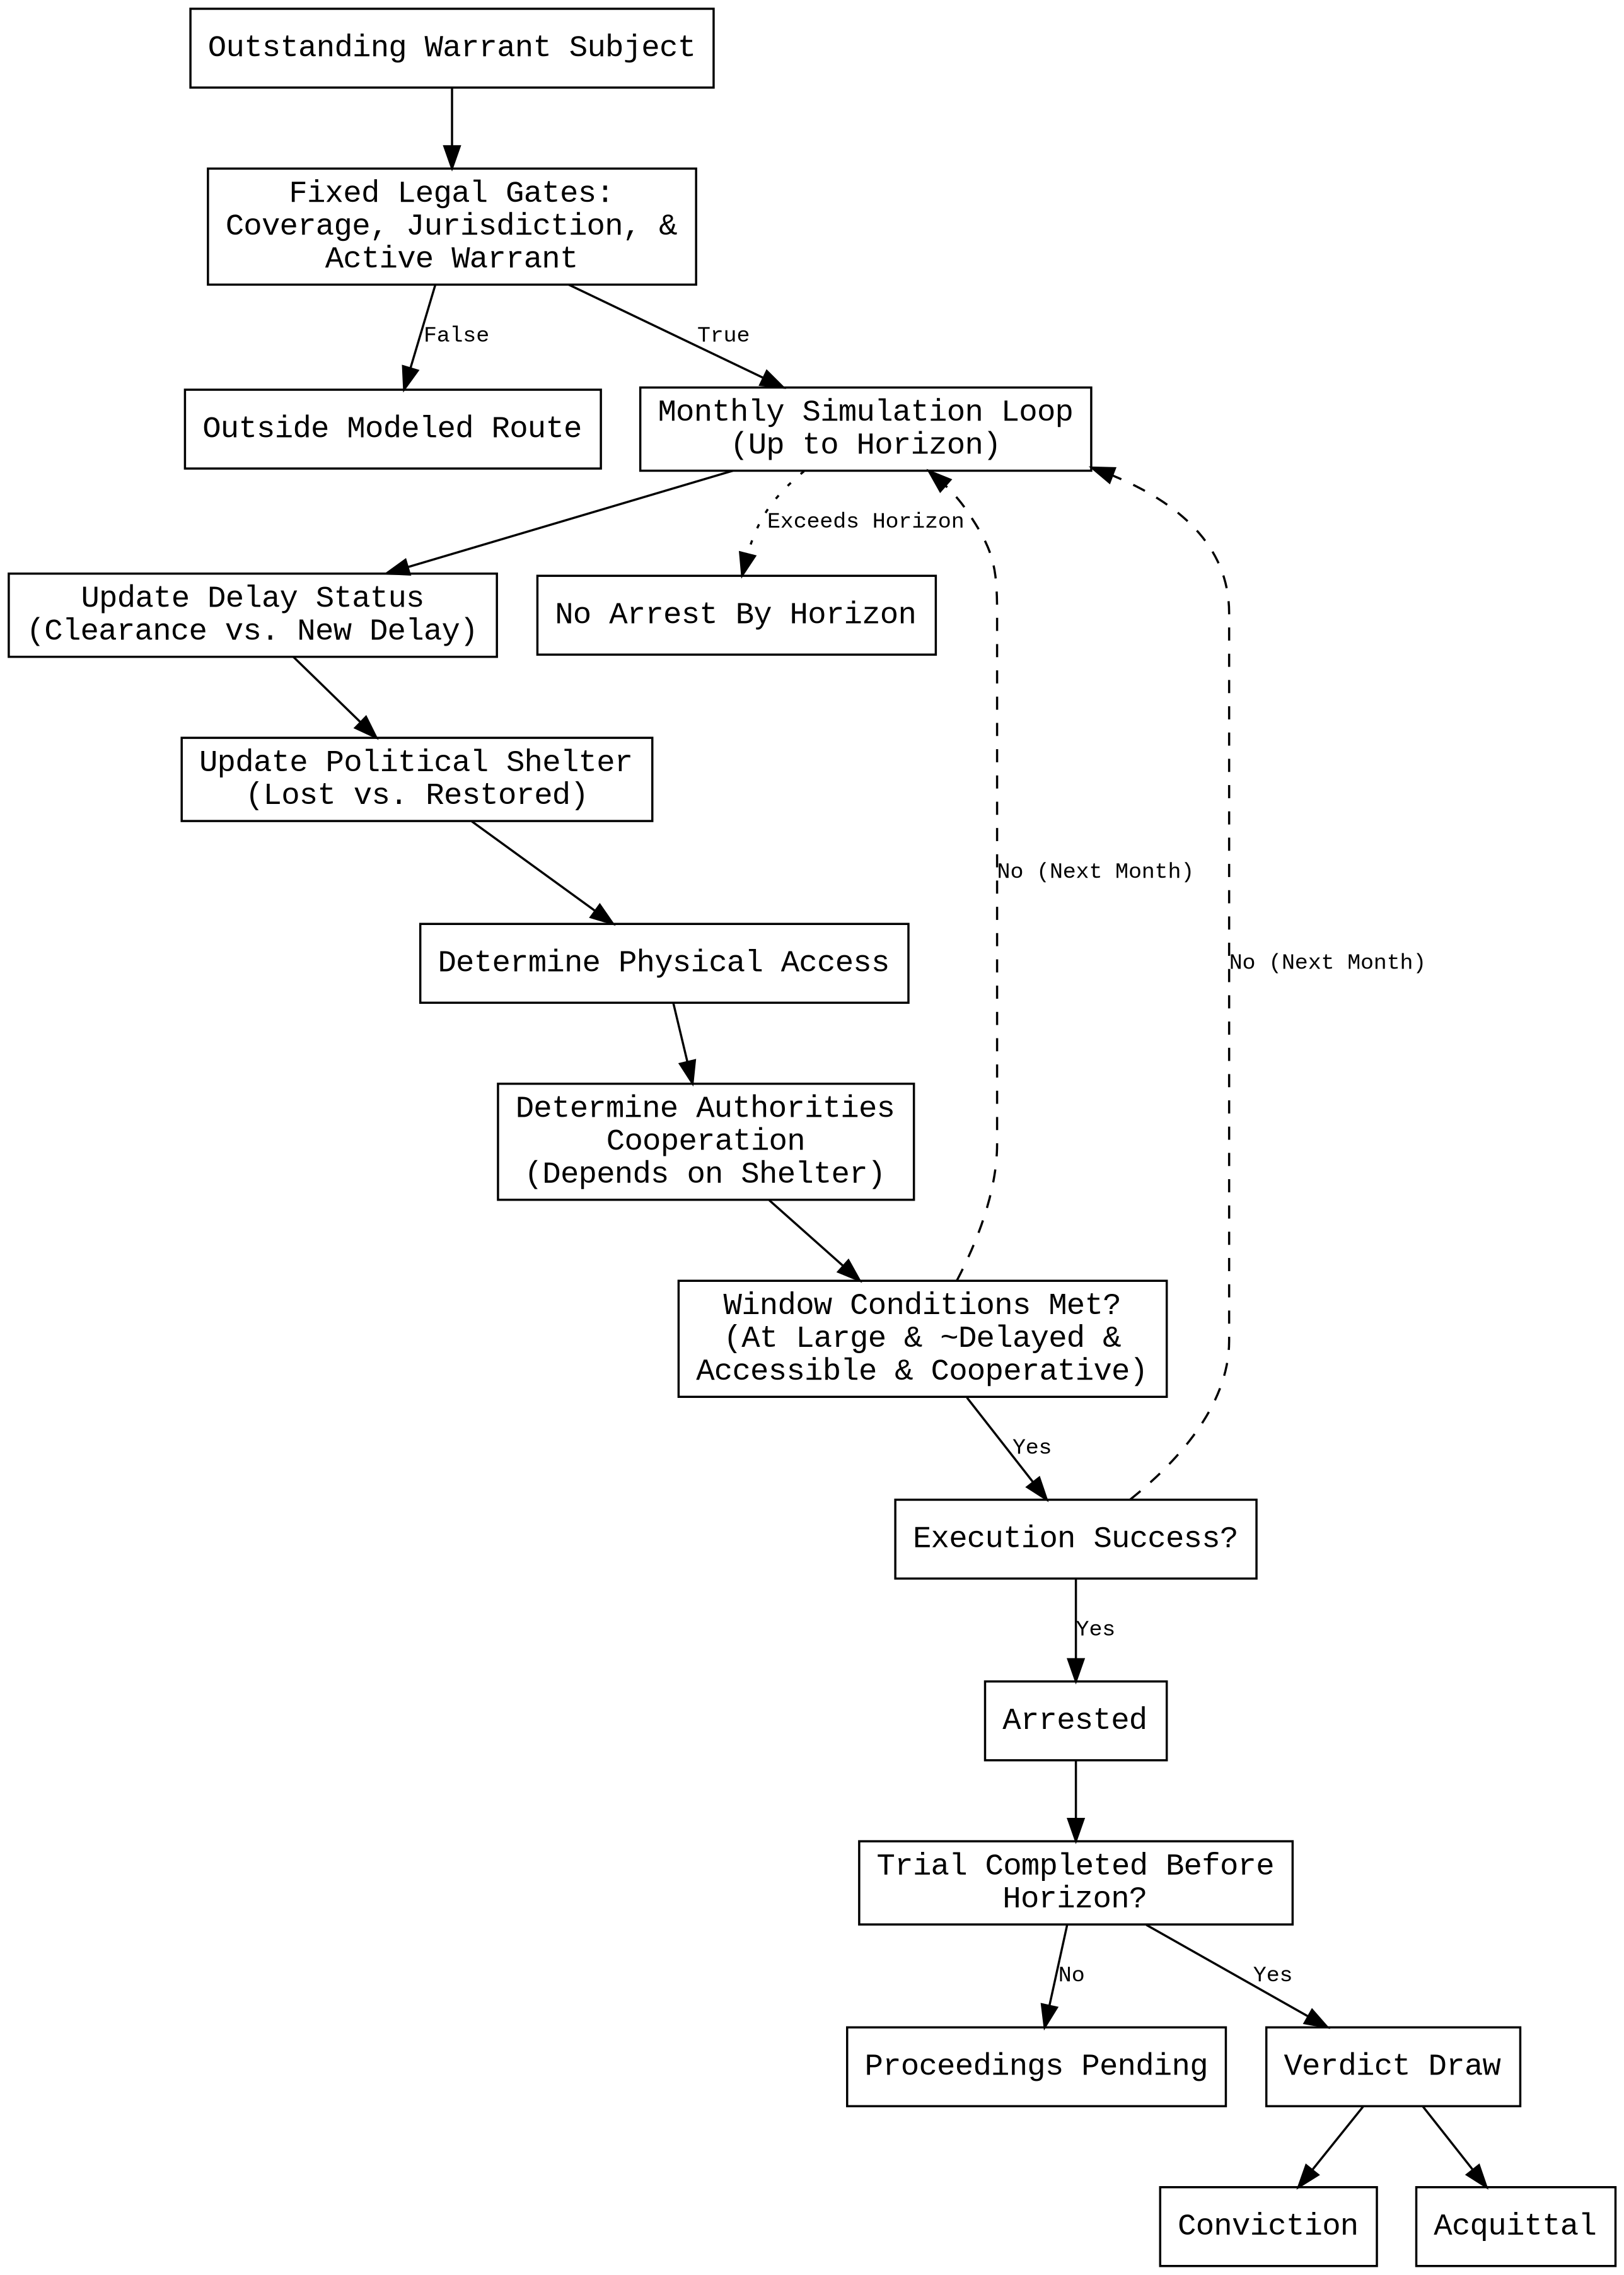

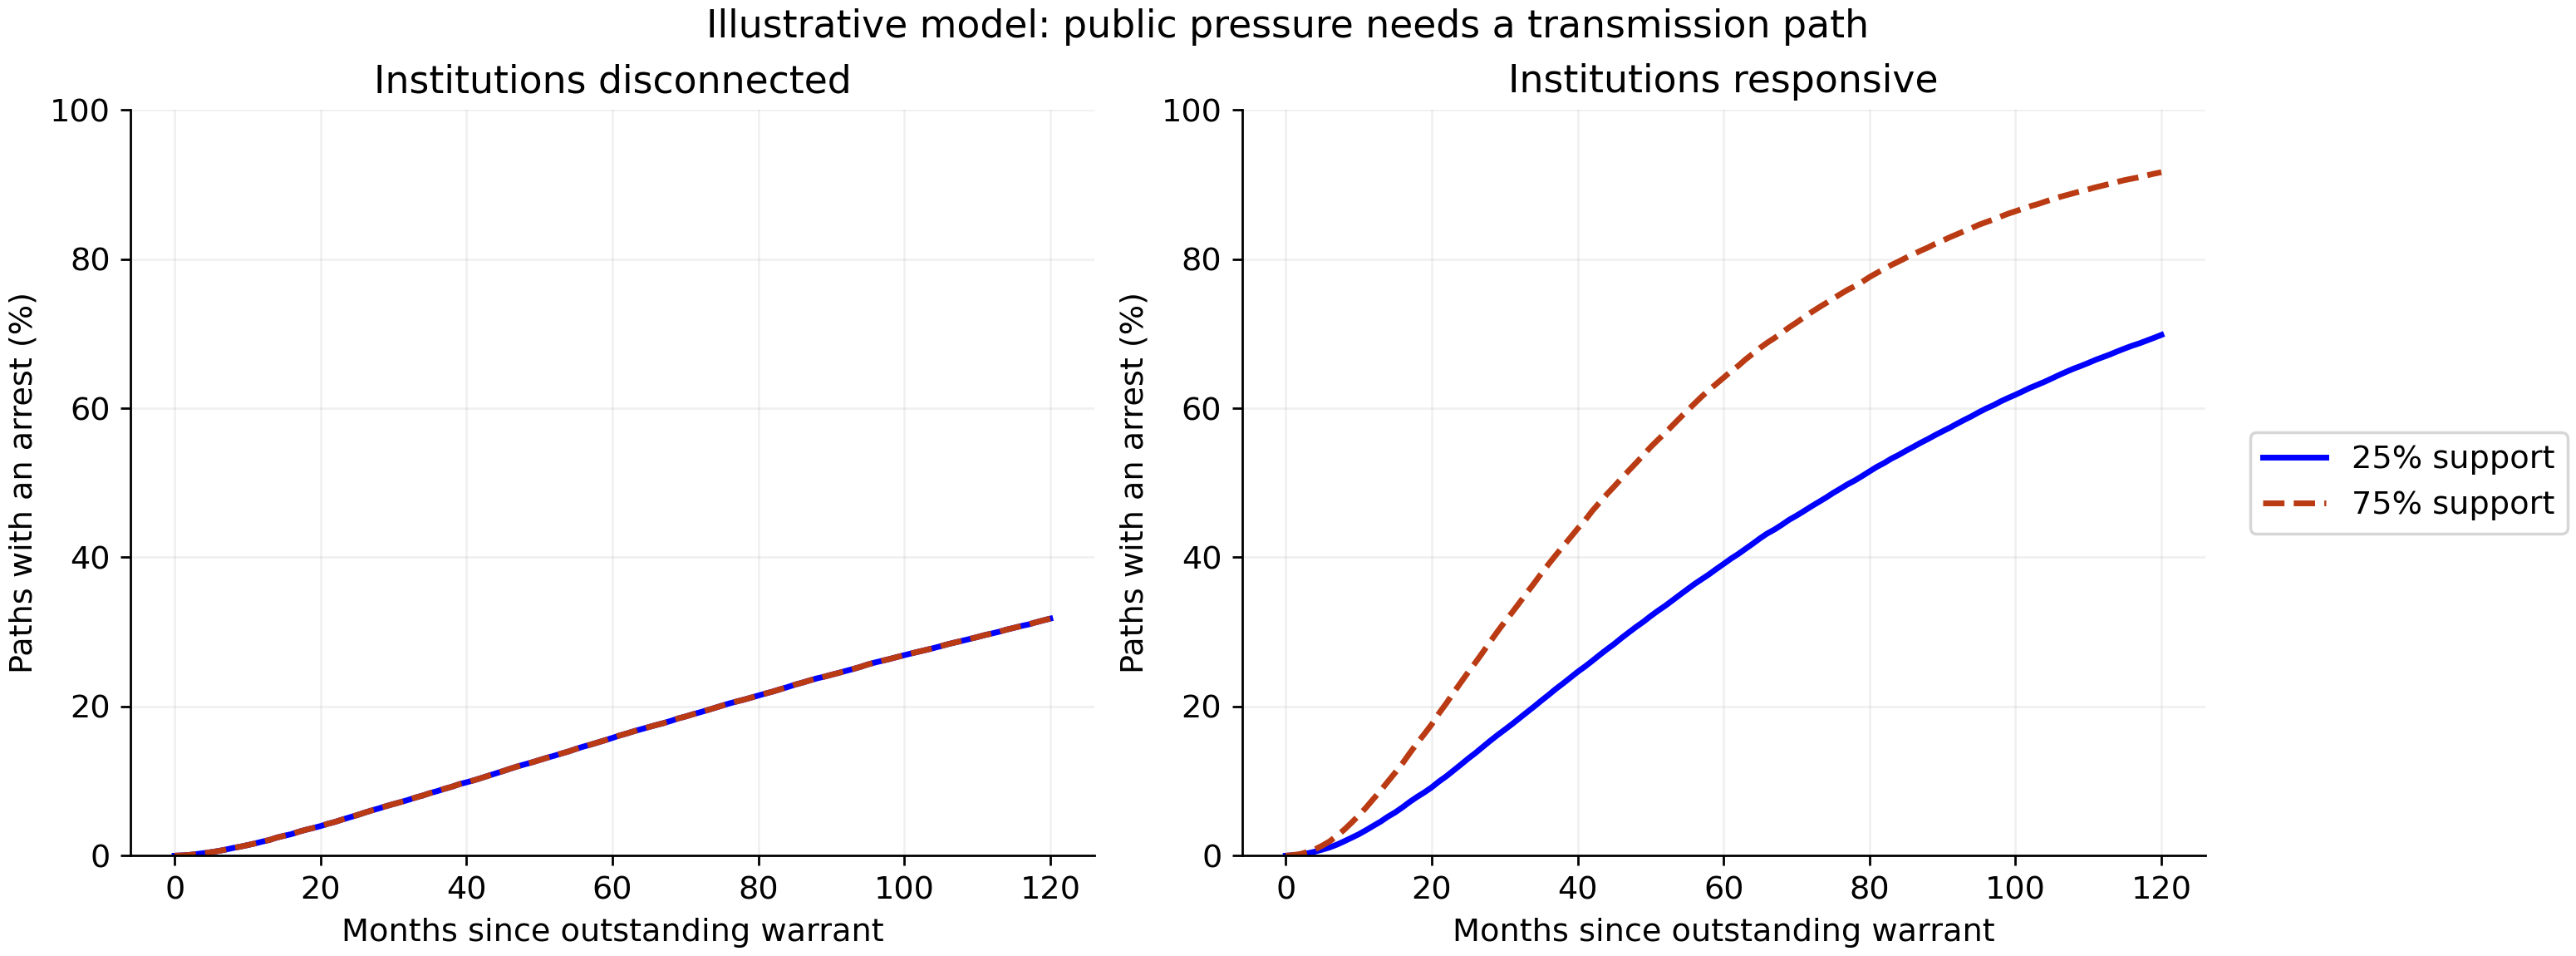

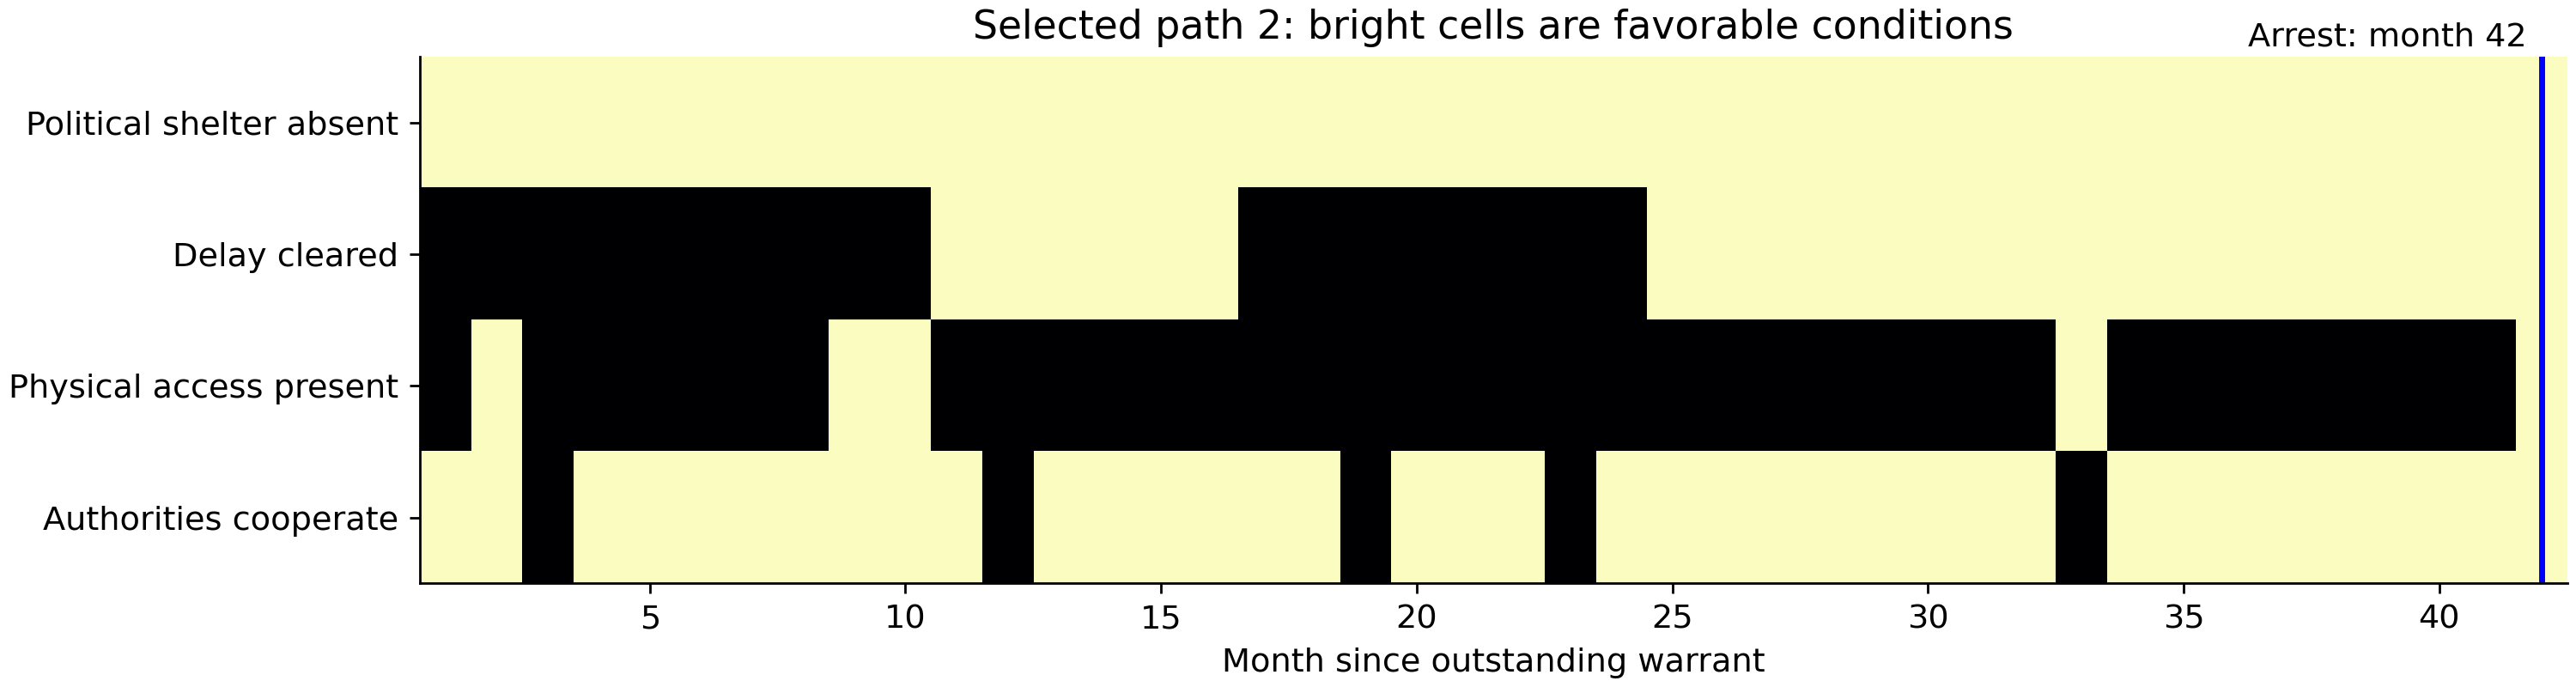

ILLUSTRATIVE ASSUMPTIONS; NO NAMED-PERSON FORECAST
Baseline: 75.3% arrested
25% support, disconnected: 31.8% arrested
75% support, disconnected: 31.8% arrested
25% support, responsive: 69.8% arrested
75% support, responsive: 91.6% arrested
Recurring delays dominate: 33.4% arrested
Faster delay clearance: 82.2% arrested
Adaptive replacement delays: 62.4% arrested
No physical access: 0.0% arrested
No pre-existing criminal coverage: 0.0% arrested


In [1]:
"""This script explores public pressure and enforcement windows with a Monte Carlo model.

All transition probabilities are illustrative assumptions. This simulator
does not estimate any named person's guilt, arrest risk, or sentence. It starts
with a hypothetical outstanding warrant and separates legal coverage from
political cooperation, temporary delays, physical access, and trial outcomes.
"""

import io
import base64
from dataclasses import asdict, dataclass, replace
from IPython.display import Image, display, HTML
import matplotlib.pyplot as plt
import numpy as np
import graphviz


# --- Control knobs - illustrative assumptions ---

@dataclass(frozen=True)
class Controls:
    """Contain adjustable probabilities and fixed legal gates."""
    paths: int = 50_000
    months: int = 120
    seed: int = 1729
    public_support: float = 0.49
    responsiveness: float = 0.65
    delay_clearance: float = 0.10
    new_delay: float = 0.08
    adaptive_new_delay_gain: float = 0.0
    adaptation_window_months: int = 3
    physical_access: float = 0.12
    sheltered_cooperation: float = 0.03
    unsheltered_cooperation: float = 0.80
    execution_success: float = 0.90
    baseline_shelter_loss: float = 0.002
    pressure_shelter_loss_gain: float = 0.040
    shelter_restoration: float = 0.006
    trial_months_min: int = 12
    trial_months_max: int = 36
    conviction_given_completed_trial: float = 0.65
    initially_sheltered: bool = True
    initially_delayed: bool = True
    criminal_coverage_at_conduct: bool = True
    jurisdiction_available: bool = True
    warrant_active: bool = True


CONTROL_KNOBS = Controls()
FIGURE_DPI = 250
TRACE_PATHS = 64
MAX_CHARACTERS_PER_LINE = 27

# Graphviz formatting controls
NODE_FONT = "DejaVu Sans"
NODE_FONT_WEIGHT = "normal"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"

plt.rcParams.update({
    "figure.dpi": FIGURE_DPI,
    "font.size": 11,
    "font.sans-serif": ["DejaVu Sans"],
    "font.weight": "normal",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
})


def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps text to a specified maximum width, hyphenating oversized strings."""
    lines = []
    for paragraph in text.split('\n'):
        current_line = ""
        words = paragraph.split()
        for word in words:
            while len(word) > max_width:
                if current_line:
                    lines.append(current_line)
                    current_line = ""
                chunk = word[:max_width - 1] + "-"
                lines.append(chunk)
                word = word[max_width - 1:]

            if current_line:
                if len(current_line) + 1 + len(word) <= max_width:
                    current_line += " " + word
                else:
                    lines.append(current_line)
                    current_line = word
            else:
                current_line = word
        if current_line:
            lines.append(current_line)
    return '\n'.join(lines)


def build_simulation_logic_tree() -> graphviz.Digraph:
    """Constructs the directed Graphviz object outlining the Monte Carlo pathways."""
    tree = graphviz.Digraph(format='png')

    tree.attr(dpi=str(FIGURE_DPI), splines=EDGE_ROUTING, bgcolor=BACKGROUND_COLOR, rankdir=RANK_DIRECTION)
    tree.attr('node', shape=NODE_SHAPE, style='solid', color=FOREGROUND_COLOR, fontcolor=FOREGROUND_COLOR, fontname=NODE_FONT)
    tree.attr('edge', color=FOREGROUND_COLOR, arrowhead='normal', fontname=NODE_FONT, fontsize='10')

    tree.node('Root', wrap_text('Outstanding Warrant Subject'))
    tree.node('LegalGate', wrap_text('Fixed Legal Gates:\nCoverage, Jurisdiction, & Active Warrant'))
    tree.node('Outside', wrap_text('Outside Modeled Route'))
    tree.node('SimLoop', wrap_text('Monthly Simulation Loop\n(Up to Horizon)'))

    tree.node('Delay', wrap_text('Update Delay Status\n(Clearance vs. New Delay)'))
    tree.node('Shelter', wrap_text('Update Political Shelter\n(Lost vs. Restored)'))
    tree.node('Access', wrap_text('Determine Physical Access'))
    tree.node('Coop', wrap_text('Determine Authorities Cooperation\n(Depends on Shelter)'))

    tree.node('Window', wrap_text('Window Conditions Met?\n(At Large & ~Delayed & Accessible & Cooperative)'))
    tree.node('Exec', wrap_text('Execution Success?'))
    tree.node('Arrest', wrap_text('Arrested'))
    tree.node('NoArrest', wrap_text('No Arrest By Horizon'))

    tree.node('Trial', wrap_text('Trial Completed Before Horizon?'))
    tree.node('Pending', wrap_text('Proceedings Pending'))
    tree.node('Verdict', wrap_text('Verdict Draw'))
    tree.node('Convict', wrap_text('Conviction'))
    tree.node('Acquit', wrap_text('Acquittal'))

    # Root to Gates
    tree.edge('Root', 'LegalGate')
    tree.edge('LegalGate', 'Outside', label='False')
    tree.edge('LegalGate', 'SimLoop', label='True')

    # Simulation Flow
    tree.edge('SimLoop', 'Delay')
    tree.edge('Delay', 'Shelter')
    tree.edge('Shelter', 'Access')
    tree.edge('Access', 'Coop')
    tree.edge('Coop', 'Window')

    # Branching from Window
    tree.edge('Window', 'Exec', label='Yes')
    tree.edge('Window', 'SimLoop', label='No (Next Month)', style='dashed')

    # Arrest Execution
    tree.edge('Exec', 'Arrest', label='Yes')
    tree.edge('Exec', 'SimLoop', label='No (Next Month)', style='dashed')

    # Exceeding Horizon
    tree.edge('SimLoop', 'NoArrest', label='Exceeds Horizon', style='dotted')

    # Post Arrest
    tree.edge('Arrest', 'Trial')
    tree.edge('Trial', 'Pending', label='No')
    tree.edge('Trial', 'Verdict', label='Yes')
    tree.edge('Verdict', 'Convict')
    tree.edge('Verdict', 'Acquit')

    return tree


def validate_controls(controls: Controls) -> None:
    """Reject invalid probabilities, time ranges, and simulation sizes."""
    for name, value in asdict(controls).items():
        if isinstance(value, float) and not 0.0 <= value <= 1.0:
            raise ValueError(f"{name} must lie in [0, 1].")
    if controls.paths < 1 or controls.months < 1:
        raise ValueError("paths and months must be positive integers.")
    if not 1 <= controls.trial_months_min <= controls.trial_months_max:
        raise ValueError("The trial-duration bounds must be positive and ordered.")
    if controls.adaptation_window_months < 0:
        raise ValueError("adaptation_window_months must be nonnegative.")
    if controls.new_delay + controls.adaptive_new_delay_gain > 1.0:
        raise ValueError("The maximum new-delay probability exceeds one.")
    if controls.baseline_shelter_loss + controls.pressure_shelter_loss_gain > 1.0:
        raise ValueError("The maximum shelter-loss probability exceeds one.")


def wilson_interval(successes: int, total: int) -> tuple[float, float]:
    """Return a 95% Wilson interval for Monte Carlo sampling uncertainty."""
    z_score = 1.959963984540054
    fraction = successes / total
    denominator = 1.0 + z_score**2 / total
    center = (fraction + z_score**2 / (2.0 * total)) / denominator
    half_width = z_score * np.sqrt(
        fraction * (1.0 - fraction) / total
        + z_score**2 / (4.0 * total**2)
    ) / denominator
    return float(center - half_width), float(center + half_width)


def simulate(controls: Controls) -> dict[str, object]:
    """Simulate monthly delays, shelter transitions, arrest, and trial branches."""
    validate_controls(controls)
    rng = np.random.default_rng(controls.seed)
    count = controls.paths
    sheltered = np.full(count, controls.initially_sheltered, dtype=bool)
    delayed = np.full(count, controls.initially_delayed, dtype=bool)
    last_clearance = np.full(count, -1_000_000, dtype=np.int32)
    arrest_month = np.full(count, -1, dtype=np.int32)
    trial_duration = rng.integers(
        controls.trial_months_min, controls.trial_months_max + 1, size=count
    )
    verdict_draw = rng.random(count)
    legal_gate = (
        controls.criminal_coverage_at_conduct
        and controls.jurisdiction_available
        and controls.warrant_active
    )
    shelter_loss = (
        controls.baseline_shelter_loss
        + controls.pressure_shelter_loss_gain
        * controls.public_support
        * controls.responsiveness
    )
    cumulative_arrests = np.zeros(controls.months + 1)
    arrest_windows = np.zeros(count, dtype=np.int32)
    new_delay_events = np.zeros(count, dtype=np.int32)
    clearance_events = np.zeros(count, dtype=np.int32)
    trace_count = min(TRACE_PATHS, count)
    traces = np.zeros((trace_count, controls.months, 5), dtype=bool)

    for index in range(controls.months):
        month = index + 1
        draws = rng.random((6, count))
        at_large = arrest_month < 0

        clears = delayed & (draws[0] < controls.delay_clearance)
        recently_cleared = (
            month - last_clearance <= controls.adaptation_window_months
        )
        new_delay_probability = (
            controls.new_delay
            + controls.adaptive_new_delay_gain * recently_cleared
        )
        emerges = ~delayed & (draws[1] < new_delay_probability)
        clearance_events += (clears & at_large).astype(np.int32)
        new_delay_events += (emerges & at_large).astype(np.int32)
        delayed = (delayed & ~clears) | emerges
        last_clearance[clears] = month

        shelter_lost = sheltered & (draws[2] < shelter_loss)
        shelter_restored = ~sheltered & (
            draws[2] < controls.shelter_restoration
        )
        sheltered = (sheltered & ~shelter_lost) | shelter_restored
        cooperation_probability = np.where(
            sheltered,
            controls.sheltered_cooperation,
            controls.unsheltered_cooperation,
        )
        accessible = draws[3] < controls.physical_access
        cooperative = draws[4] < cooperation_probability
        window = legal_gate & at_large & ~delayed & accessible & cooperative
        arrest_windows += window.astype(np.int32)
        arrested_now = window & (draws[5] < controls.execution_success)
        arrest_month[arrested_now] = month
        cumulative_arrests[month] = np.mean(arrest_month >= 0)
        traces[:, index, :] = np.column_stack((
            sheltered[:trace_count],
            delayed[:trace_count],
            accessible[:trace_count],
            cooperative[:trace_count],
            arrested_now[:trace_count],
        ))

    arrested = arrest_month >= 0
    trial_completed = arrested & (
        arrest_month + trial_duration <= controls.months
    )
    convicted = trial_completed & (
        verdict_draw < controls.conviction_given_completed_trial
    )
    acquitted = trial_completed & ~convicted
    pending = arrested & ~trial_completed
    statuses = {
        "no_arrest_by_horizon": int(np.count_nonzero(~arrested)),
        "proceedings_pending": int(np.count_nonzero(pending)),
        "conviction": int(np.count_nonzero(convicted)),
        "acquittal": int(np.count_nonzero(acquitted)),
    }
    if not legal_gate:
        statuses = {"outside_modeled_icc_route": count}
    arrest_count = int(np.count_nonzero(arrested))
    intervals = {
        name: wilson_interval(value, count) for name, value in statuses.items()
    }
    conditional_median = (
        float(np.median(arrest_month[arrested])) if arrest_count else None
    )
    return {
        "controls": asdict(controls),
        "legal_gate": legal_gate,
        "status_counts": statuses,
        "status_fractions": {
            name: value / count for name, value in statuses.items()
        },
        "status_mc95_intervals": intervals,
        "arrest_fraction": arrest_count / count,
        "arrest_mc95_interval": wilson_interval(arrest_count, count),
        "median_month_among_arrested": conditional_median,
        "mean_pre_arrest_windows": float(np.mean(arrest_windows)),
        "mean_pre_arrest_new_delays": float(np.mean(new_delay_events)),
        "mean_pre_arrest_delay_clearances": float(np.mean(clearance_events)),
        "cumulative_arrests": cumulative_arrests,
        "arrest_month": arrest_month,
        "traces": traces,
    }


def scenario_controls(base: Controls) -> dict[str, Controls]:
    """Construct paired and timing scenarios from the same baseline controls."""
    return {
        "Baseline": base,
        "25% support, disconnected": replace(
            base, public_support=0.25, responsiveness=0.0
        ),
        "75% support, disconnected": replace(
            base, public_support=0.75, responsiveness=0.0
        ),
        "25% support, responsive": replace(
            base, public_support=0.25, responsiveness=1.0
        ),
        "75% support, responsive": replace(
            base, public_support=0.75, responsiveness=1.0
        ),
        "Recurring delays dominate": replace(
            base, delay_clearance=0.03, new_delay=0.25
        ),
        "Faster delay clearance": replace(base, delay_clearance=0.30),
        "Adaptive replacement delays": replace(
            base, adaptive_new_delay_gain=0.30
        ),
        "No physical access": replace(base, physical_access=0.0),
        "No pre-existing criminal coverage": replace(
            base, criminal_coverage_at_conduct=False
        ),
    }


def render_figures(
    results: dict[str, dict[str, object]]
) -> None:
    """Render paired comparisons, one enforcement history, and the Graphviz tree in memory."""
    # Render Graphviz Logic Tree
    logic_tree = build_simulation_logic_tree()
    binary_png = logic_tree.pipe(format='png')
    display(Image(data=binary_png))
    encoded_image = base64.b64encode(binary_png).decode('utf-8')
    html_interface = f'''
    <a download="monte_carlo_logic_tree.png" href="data:image/png;base64,{encoded_image}" target="_blank">
        <button style="padding: 8px 16px; background-color: {BACKGROUND_COLOR}; color: {FOREGROUND_COLOR}; border: 2px solid {FOREGROUND_COLOR}; cursor: pointer; font-family: {NODE_FONT}; font-weight: {NODE_FONT_WEIGHT}; margin-top: 10px; margin-bottom: 20px;">
            Download Logic Tree PNG
        </button>
    </a>
    '''
    display(HTML(html_interface))

    # Render Matplotlib Plots
    fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6), constrained_layout=True)
    for axis, mode in zip(axes, ("disconnected", "responsive")):
        for support, color in ((25, "#0000FF"), (75, "#BA3B13")):
            result = results[f"{support}% support, {mode}"]
            values = result["cumulative_arrests"]
            axis.plot(
                np.arange(len(values)),
                100.0 * values,
                color=color,
                linestyle="--" if support == 75 else "-",
                linewidth=2,
                label=f"{support}% support",
            )
        axis.set(
            xlabel="Months since outstanding warrant",
            ylabel="Paths with an arrest (%)",
            ylim=(0, 100),
            title=f"Institutions {mode}",
        )
    axes[1].legend(loc="center left", bbox_to_anchor=(1.03, 0.5))
    fig.suptitle("Illustrative model: public pressure needs a transmission path")

    buffer_comp = io.BytesIO()
    fig.savefig(buffer_comp, format="png", dpi=FIGURE_DPI)
    display(Image(data=buffer_comp.getvalue(), format="png"))
    plt.close(fig)

    baseline = results["Baseline"]
    histories = baseline["traces"]
    arrests = baseline["arrest_month"][: len(histories)]
    candidates = np.flatnonzero((arrests >= 24) & (arrests <= 105))
    path_index = int(candidates[0]) if len(candidates) else 0
    endpoint = int(arrests[path_index])
    endpoint = endpoint if endpoint >= 0 else CONTROL_KNOBS.months
    history = histories[path_index, :endpoint]

    favorable = np.stack((
        ~history[:, 0], ~history[:, 1], history[:, 2], history[:, 3]
    ))
    fig, axis = plt.subplots(figsize=(12.0, 3.2), constrained_layout=True)
    axis.grid(False)
    axis.imshow(
        favorable.astype(float), cmap="magma", vmin=0, vmax=1,
        aspect="auto", interpolation="nearest",
        extent=(0.5, endpoint + 0.5, 3.5, -0.5),
    )
    axis.set_yticks(range(4), [
        "Political shelter absent", "Delay cleared",
        "Physical access present", "Authorities cooperate",
    ])
    axis.set_xlabel("Month since outstanding warrant")
    axis.set_title(
        f"Selected path {path_index}: bright cells are favorable conditions"
    )
    if arrests[path_index] >= 0:
        axis.axvline(endpoint, color="#0000FF", linewidth=2)
        axis.annotate(
            f"Arrest: month {endpoint}", xy=(endpoint, -0.45),
            xytext=(-5, 6), textcoords="offset points", ha="right",
        )

    buffer_win = io.BytesIO()
    fig.savefig(buffer_win, format="png", dpi=FIGURE_DPI)
    display(Image(data=buffer_win.getvalue(), format="png"))
    plt.close(fig)


def print_results(
    results: dict[str, dict[str, object]]
) -> None:
    """Print scenario fractions and sampling intervals directly to standard output."""
    for name, result in results.items():
        arrest_pct = round(100.0 * result["arrest_fraction"], 3)
        print(f"{name}: {arrest_pct:.1f}% arrested")


def main() -> None:
    """Run all scenarios, verify causal boundary cases, and display outputs."""
    results = {
        name: simulate(controls)
        for name, controls in scenario_controls(CONTROL_KNOBS).items()
    }
    low = results["25% support, disconnected"]
    high = results["75% support, disconnected"]
    if not np.array_equal(low["arrest_month"], high["arrest_month"]):
        raise AssertionError("Disconnected public support changed arrest paths.")
    if results["No physical access"]["arrest_fraction"] != 0.0:
        raise AssertionError("An arrest occurred without physical access.")
    if results["No pre-existing criminal coverage"]["arrest_fraction"] != 0.0:
        raise AssertionError("An arrest occurred without the fixed legal gate.")
    for result in results.values():
        if sum(result["status_counts"].values()) != CONTROL_KNOBS.paths:
            raise AssertionError("Terminal branches do not partition the paths.")
        if np.any(np.diff(result["cumulative_arrests"]) < 0.0):
            raise AssertionError("Cumulative arrests decreased.")

    render_figures(results)
    print("ILLUSTRATIVE ASSUMPTIONS; NO NAMED-PERSON FORECAST")
    print_results(results)


if __name__ == "__main__":
    main()